# Combining transients: a mixed SN Ia and core-collapse sample

Real surveys do not observe one kind of transient at a time: a photometric sample of supernovae mixes
Type Ia and core-collapse (CC) supernovae. Simulating such mixed samples helps to understand
the contamination of a sample, or to train a photometric classifier.

In this example, you will simulate SNe Ia together with SNe II, Ib and Ic, in proportion to their rates,
observe them with a ZTF-like survey, and see how the composition of the sample changes once a detection
criterion is applied.

In [1]:
import numpy as np
import pandas
import matplotlib.pyplot as plt
from astropy.time import Time
from ztffields import Fields

import skysurvey

## Draw each population

Each transient class is drawn independently with {meth}`~skysurvey.SNeIa.from_draw`, using the same time window,
redshift range and sky area. Since we give `tstart`/`tstop` and no `size`, the number of targets of each class
follows from its own volumetric rate (see the [SN Ia](transientclasses/sne_ia.ipynb) and
[CC SN](transientclasses/sne_cc.ipynb) reference pages).

In [2]:
draw_kwargs = dict(tstart="2026-01-15", tstop="2026-04-15", zmax=0.1,
                   radec={"dec_range": [-30, 90]})  # the sky visible from Palomar

populations = [skysurvey.SNeIa.from_draw(**draw_kwargs),
               skysurvey.SNeII.from_draw(**draw_kwargs),
               skysurvey.SNeIb.from_draw(**draw_kwargs),
               skysurvey.SNeIc.from_draw(**draw_kwargs)]
for target in populations:
    print(f"{target.kind:6s}: {len(target.data):,} targets")

SNIa  : 1,233 targets
SN II : 3,407 targets
SN Ib : 567 targets
SN Ic : 393 targets


Although SNe Ia are the most studied, CC SNe are three to four times more frequent in this volume.

## Gather them in a collection

A {class}`~skysurvey.target.collection.TargetCollection` groups several targets. Its `data` concatenates their
data, with two extra columns: `kind`, the type of each transient, and `subindex`, its index in the original target.
Columns that do not apply to a given type (e.g. `x1` and `c` for CC SNe) are `NaN`:

In [3]:
mixed = skysurvey.TargetCollection(populations)
mixed.data.sample(5, random_state=1)

,kind,subindex,z,x1,c,t0,ra,dec,magabs,magobs,template
4704,SN Ib,64,0.01295,NaN,NaN,61103.957031,242.293762,-1.411905,-17.864841,15.950301,v19-2009iz-corr
5570,SN Ic,363,0.08355,NaN,NaN,61058.359375,296.999939,8.828970,-17.315193,20.657824,v19-2007gr-corr
250,SNIa,250,0.08655,1.82,2.775558e-16,61111.816406,271.146362,-28.660715,-19.417543,18.636484,salt2
1727,SN II,494,0.08675,NaN,NaN,61057.214844,170.682434,-9.124385,-16.249371,21.809961,v19-2009n-corr
2610,SN II,1377,0.01815,NaN,NaN,61112.812500,301.384003,4.883309,-17.950977,16.605658,v19-2016x-corr


## A ZTF-like survey

To observe them, we build mock ZTF observing logs for a 4-month season: every night, 250 random fields of the
ZTF primary grid are observed in $g$ and then in $r$. Each exposure covers the 64 CCD quadrants of the camera,
with a sky noise drawn between 10 and 20 (in flux units for a zero point of 25), i.e. a 5$\sigma$ depth of about
20.5 mag.

In [4]:
rng = np.random.default_rng(42)
fields = Fields.FIELDS_RADEC  # ZTF field centers
primary = fields[(fields.index < 880) & (fields["dec"] > -30)].index.to_numpy()

nights = Time("2026-01-01").mjd + np.arange(120)
fieldid = np.concatenate([rng.choice(primary, size=250, replace=False) for _ in nights])
mjd = np.repeat(nights, 250) + rng.uniform(0.1, 0.4, size=len(fieldid))
exposures = pandas.DataFrame({"fieldid": np.tile(fieldid, 2),
                              "band": np.repeat(["ztfg", "ztfr"], len(fieldid)),
                              "mjd": np.concatenate([mjd, mjd + 0.05]),  # r one hour after g
                              "skynoise": rng.uniform(10, 20, size=2 * len(fieldid)),
                              "gain": 1., "zp": 25.})

Each exposure is then expanded into its 64 quadrants (`rcid`), and loaded with {meth}`skysurvey.ZTF.from_pointings`:

In [5]:
logs = exposures.loc[exposures.index.repeat(64)].reset_index(drop=True)
logs["rcid"] = np.tile(np.arange(64), len(exposures))
ztf = skysurvey.ZTF.from_pointings(logs)
print(f"{len(exposures):,} exposures, {len(logs):,} quadrant observations")

60,000 exposures, 3,840,000 quadrant observations


## Simulate the dataset

A collection is used exactly like a single target: {meth}`skysurvey.DataSet.from_targets_and_survey` simulates the
light curves of every target, each with its own template.

In [6]:
dset = skysurvey.DataSet.from_targets_and_survey(mixed, ztf, seed=42)
dset.data.head()

mjd  band   skynoise  gain    zp  fieldid  rcid  \
index index_obs                                                             
0     74561      61045.226562  ztfg  14.652531   1.0  25.0      416     1   
      1994561    61045.277344  ztfr  11.823300   1.0  25.0      416     1   
      125313     61048.332031  ztfg  18.212263   1.0  25.0      416     1   
      2045313    61048.382812  ztfr  14.562869   1.0  25.0      416     1   
      207937     61053.175781  ztfg  18.465458   1.0  25.0      416     1   

                      flux    fluxerr  
index index_obs                        
0     74561       4.464876  14.652531  
      1994561   -12.296045  11.823301  
      125313     13.667415  18.212263  
      2045313    13.697321  14.562869  
      207937    -36.026759  18.465458

The light curves are indexed by the index of `mixed.data` (stored as `dset.targets.data`), so you can always
retrieve the type of a target. Let us look at the light curves of a SN Ia and a SN Ic, among the well-sampled ones:

In [7]:
ndetections = dset.get_ndetection()  # number of 5-sigma detections per target
kind = dset.targets.data["kind"]

well_sampled = ndetections[ndetections >= 20].index
index_ia = kind.loc[well_sampled][lambda s: s == "SNIa"].index[0]
index_ic = kind.loc[well_sampled][lambda s: s == "SN Ic"].index[0]
print(f"SN Ia: index {index_ia}, SN Ic: index {index_ic}")

SN Ia: index 0, SN Ic: index 5208


To plot them, we combine the simulated observations, from {meth}`~skysurvey.DataSet.get_target_lightcurve`, with the
true model of the target. The latter is obtained from the original population (identified by `kind`, with the
target's `subindex`), with `get_template()`:

In [8]:
targets_by_kind = {target.kind: target for target in populations}

def show_lightcurve(index, ax):
    """Plot the simulated observations and the true light curve of the target `index`."""
    kind_, subindex, t0, z = dset.targets.data.loc[index, ["kind", "subindex", "t0", "z"]]
    model = targets_by_kind[kind_].get_template(index=subindex, as_model=True, set_magabs=True)
    lc = dset.get_target_lightcurve(index)
    times = np.linspace(lc["mjd"].min(), lc["mjd"].max(), 300)
    for band, color in [("ztfg", "tab:green"), ("ztfr", "tab:red")]:
        obs = lc[lc["band"] == band]
        ax.errorbar(obs["mjd"] - t0, obs["flux"], yerr=obs["fluxerr"], fmt="o", ms=3, color=color, label=band)
        ax.plot(times - t0, model.bandflux(band, times, zp=25, zpsys="ab"), color=color)
    ax.set(xlabel="Days from t0", title=f"{kind_}, z = {z:.3f}")

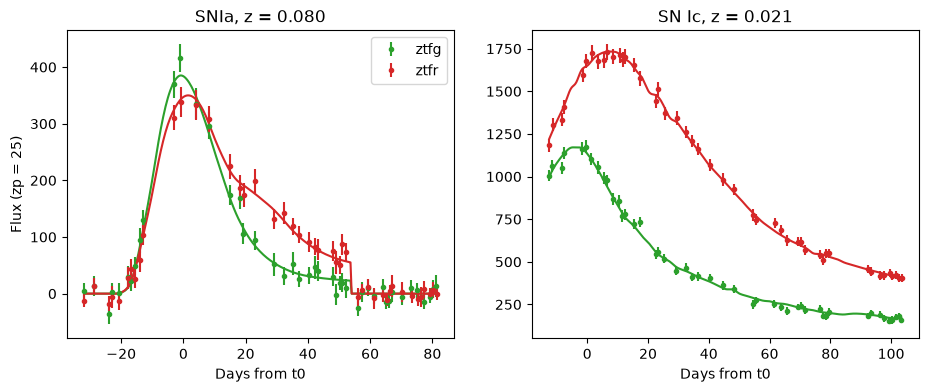

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
show_lightcurve(index_ia, axes[0])
show_lightcurve(index_ic, axes[1])
axes[0].set_ylabel("Flux (zp = 25)")
axes[0].legend();

## Sample composition

Not all targets are detected: CC SNe are on average 1.5 to 2 mag fainter than SNe Ia, so they drop out of the sample
at lower redshift. Let us call *detected* a target with at least 5 detections at $5\sigma$, and compare the composition
of the full and the detected samples:

In [10]:
detected = ndetections[ndetections >= 5].index
composition = pandas.DataFrame({"all": kind.value_counts(),
                                "detected": kind.loc[detected].value_counts()})
composition["fraction detected"] = composition["detected"] / composition["all"]
composition["share of all"] = composition["all"] / composition["all"].sum()
composition["share of detected"] = composition["detected"] / composition["detected"].sum()
composition.round(2)

,all,detected,fraction detected,share of all,share of detected
kind,,,,,
SN II,3407,1678,0.49,0.61,0.52
SNIa,1233,1032,0.84,0.22,0.32
SN Ib,567,269,0.47,0.10,0.08
SN Ic,393,219,0.56,0.07,0.07


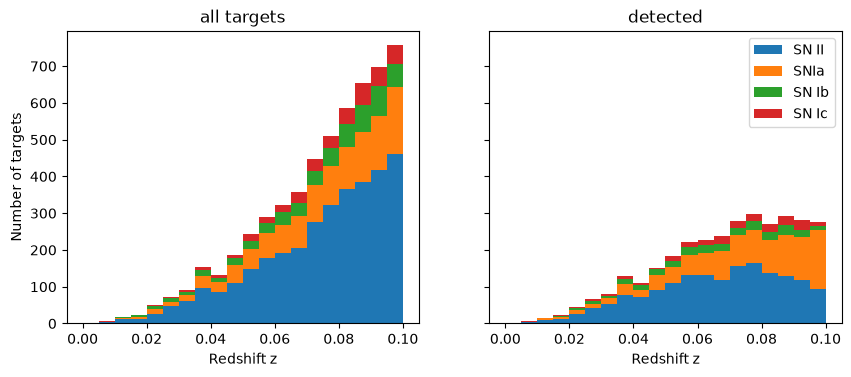

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (label, index) in zip(axes, [("all targets", kind.index), ("detected", detected)]):
    data = dset.targets.data.loc[index]
    zs = [data.loc[data["kind"] == k, "z"] for k in composition.index]
    ax.hist(zs, bins=np.linspace(0, 0.1, 21), stacked=True, label=list(composition.index))
    ax.set(xlabel="Redshift z", title=label)
axes[0].set_ylabel("Number of targets")
axes[1].legend();

Most SNe Ia are detected, while about half of the CC SNe are missed. The share of SNe Ia thus grows from about a
fifth of all targets to about a third of the detected sample, and at the highest redshifts SNe Ia become as numerous
as SNe II. This is a classic selection effect (Malmquist bias), which `skysurvey` reproduces naturally since each
target carries its own template, rate and luminosity function.

## Next steps

- [SN Ia](transientclasses/sne_ia.ipynb) and [CC SN](transientclasses/sne_cc.ipynb) reference pages, for the default
  model of each class.
- [Change the rate](howto/change_rate.ipynb) of a population, e.g. to test the impact of the CC SN rate on the contamination.
- [A realistic ZTF analysis](analysisexamples/ztf_volumelimited_rates.ipynb), using the real observing logs.